# Observatorio Inmobiliario CABA — Análisis Avanzado & Showcase Ejecutivo (End-to-End)

Este notebook consolida en un único artefacto ejecutable los hallazgos de negocio, auditoría estadística, inteligencia delictiva geoespacial, modelado predictivo y gobernanza MLOps del proyecto **Corporate Relocation / RR.HH. en CABA**.

### Las 5 Preguntas de Negocio Clave
- **Q1:** ¿Qué zonas y segmentos de departamentos de CABA ofrecen el mejor equilibrio entre calidad ambiental (`<= 65 dBA`, menor gravedad delictiva) y conectividad/servicios según el perfil (`FAMILIA` vs. `SOLTERO_EJECUTIVO`)?
- **Q2:** ¿Cuál es el impacto estadísticamente significativo de las externalidades urbanas (ruido diurno, delito, subte, escuelas) sobre el `precio_m2_total_ars` y el `costo_total_ars`?
- **Q3:** ¿Qué proporción de la oferta presenta sobreprecio o subvaluación frente al precio justo teórico explicado por atributos físicos, amenities y entorno?
- **Q4:** ¿Cómo afectan las inconsistencias de publicación (mascotas, expensas omitidas, dolarización y coordenadas) a la elegibilidad corporativa?
- **Q5:** ¿Qué subconjunto de máximo 10 variables ortogonales (`VIF < 5.0`) concentra mayor poder predictivo e información mutua para estimar `costo_total_ars` sin redundancia?

In [1]:
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import xgboost as xgb

# Resolución robusta del root del proyecto (funciona desde raíz o notebooks/)
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "config" / "settings.py").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "config" / "settings.py").exists(), "No se encontró el root del proyecto."

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
})

# Carga de datasets curados, enriquecidos, inferencia y artefactos MLOps v1
df_enr = pd.read_csv(PROJECT_ROOT / "etl/output/dataset_enriquecido_completo.csv")
df_inf = pd.read_csv(PROJECT_ROOT / "mlops/resultados_inferencia_caba.csv")
df_delitos = pd.read_csv(PROJECT_ROOT / "Datasets/Curados/delitos_2022_curado.csv")
eda_stats = json.loads((PROJECT_ROOT / "etl/output/eda_stats.json").read_text(encoding="utf-8"))
registry = json.loads((PROJECT_ROOT / "mlops/registry.json").read_text(encoding="utf-8"))

# Unir dataset enriquecido con inferencia por listing_id
df = df_enr.merge(
    df_inf[[
        "listing_id", "cluster_id", "cluster_label", "precio_justo_ars",
        "pct_sobreprecio", "pct_ahorro", "score_familia", "recomendacion_familia",
        "score_soltero_ejecutivo", "recomendacion_soltero_ejecutivo"
    ]],
    on="listing_id",
    how="inner",
)

print(f"Root del proyecto: {PROJECT_ROOT}")
print(f"Propiedades integradas (ETL + Inferencia): {len(df):,} filas x {df.shape[1]} columnas")
print(f"Registros de delitos GCBA curados:         {len(df_delitos):,} filas")
print(f"Modelo en producción (registry.json):      {registry['production_version']} (min_r2={registry['min_r2_threshold']})")

Root del proyecto: /home/luka/Documents/CapstoneProject
Propiedades integradas (ETL + Inferencia): 964 filas x 62 columnas
Registros de delitos GCBA curados:         138,528 filas
Modelo en producción (registry.json):      v1 (min_r2=0.8)


---
## 1. Auditoría ETL, Calidad de Datos y Asimetría del Target (`Q4`)

Antes de modelar, auditamos la estructura de precios, la fuerte asimetría positiva del target (`costo_total_ars`, `skew = 4.36`), la imputación de expensas y la tasa real de admisión de mascotas curada con NLP anti-negaciones.

costo_total_ars -> Mediana: $1,325,000 ARS | IQR: $800,000 ARS
Asimetría raw: 4.35 -> log1p: 1.15 | Shapiro-Wilk W=0.6229, p=1.61e-41
Expensas imputadas: 5.3% | Apto mascotas real (NLP): 27.6% | Publicados en USD: 22.4%


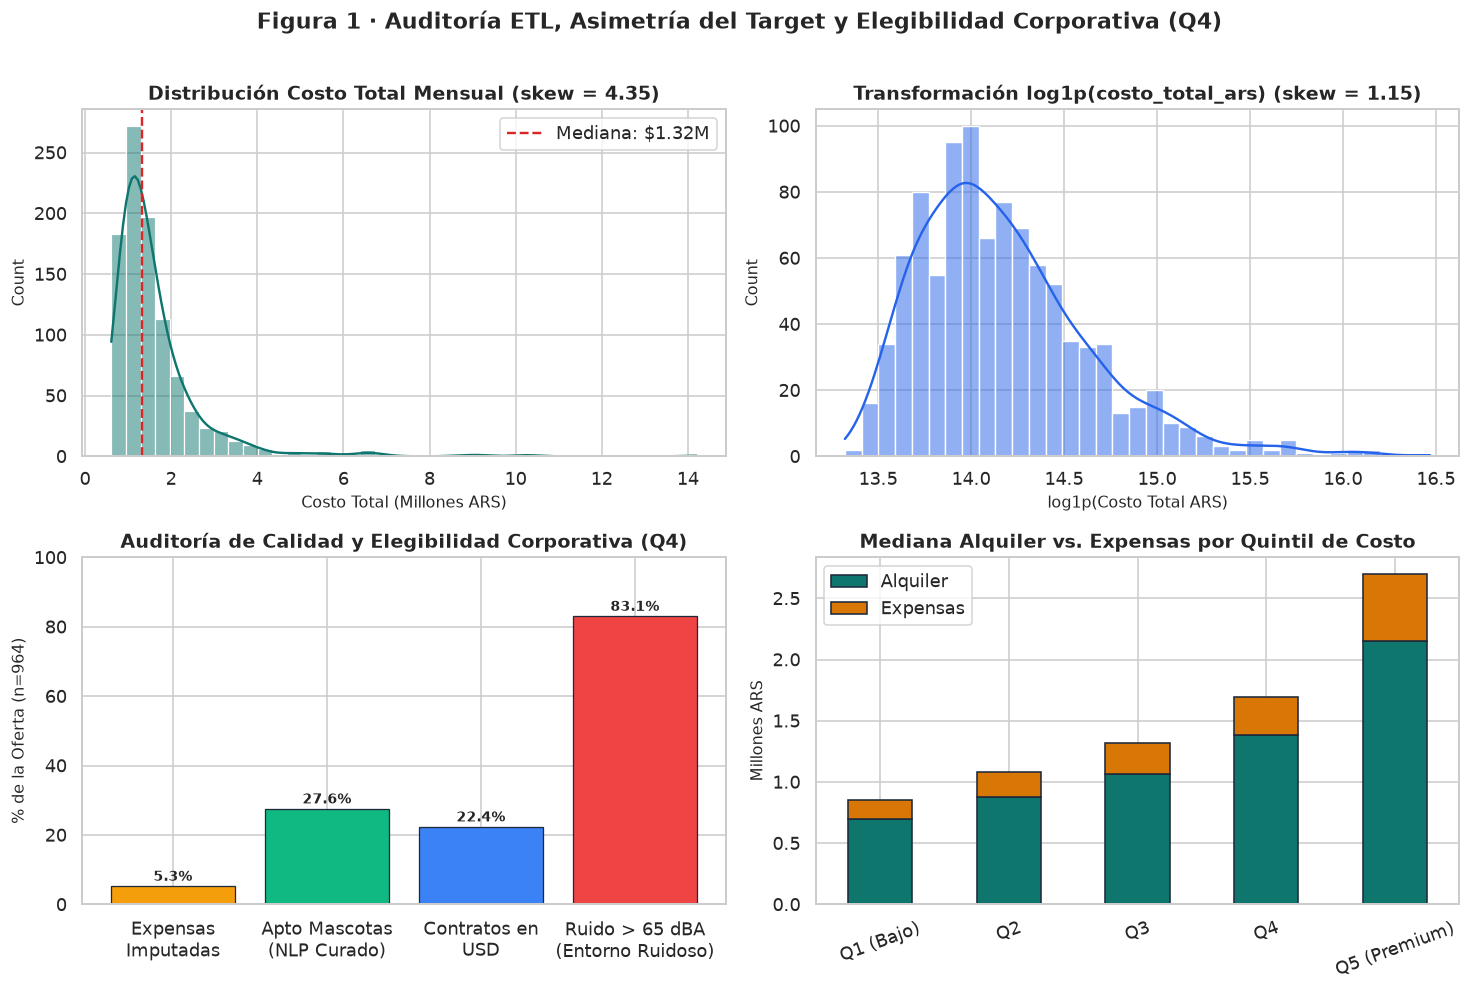

In [2]:
# Auditoría Q4: asimetría, expensas imputadas, mascotas y dolarización
skew_raw = stats.skew(df["costo_total_ars"])
skew_log = stats.skew(np.log1p(df["costo_total_ars"]))
shapiro_w, shapiro_p = stats.shapiro(df["costo_total_ars"])
pct_exp_imp = df["expensas_imputadas"].mean() * 100
pct_pets = df["apto_mascotas"].mean() * 100
pct_usd = (df["moneda_origen"].astype(str).str.upper() == "USD").mean() * 100

print(f"costo_total_ars -> Mediana: ${df['costo_total_ars'].median():,.0f} ARS | IQR: ${(df['costo_total_ars'].quantile(0.75)-df['costo_total_ars'].quantile(0.25)):,.0f} ARS")
print(f"Asimetría raw: {skew_raw:.2f} -> log1p: {skew_log:.2f} | Shapiro-Wilk W={shapiro_w:.4f}, p={shapiro_p:.2e}")
print(f"Expensas imputadas: {pct_exp_imp:.1f}% | Apto mascotas real (NLP): {pct_pets:.1f}% | Publicados en USD: {pct_usd:.1f}%")

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

# 1A: Distribución raw costo_total_ars
sns.histplot(df["costo_total_ars"] / 1e6, bins=40, kde=True, color="#0F766E", ax=axes[0, 0])
axes[0, 0].axvline(df["costo_total_ars"].median() / 1e6, color="#DC2626", linestyle="--", label=f"Mediana: ${df['costo_total_ars'].median()/1e6:.2f}M")
axes[0, 0].set_title(f"Distribución Costo Total Mensual (skew = {skew_raw:.2f})")
axes[0, 0].set_xlabel("Costo Total (Millones ARS)")
axes[0, 0].legend()

# 1B: Distribución log1p(costo_total_ars)
sns.histplot(np.log1p(df["costo_total_ars"]), bins=35, kde=True, color="#2563EB", ax=axes[0, 1])
axes[0, 1].set_title(f"Transformación log1p(costo_total_ars) (skew = {skew_log:.2f})")
axes[0, 1].set_xlabel("log1p(Costo Total ARS)")

# 1C: Auditoría de elegibilidad Q4
audit_labels = ["Expensas\nImputadas", "Apto Mascotas\n(NLP Curado)", "Contratos en\nUSD", "Ruido > 65 dBA\n(Entorno Ruidoso)"]
audit_vals = [pct_exp_imp, pct_pets, pct_usd, (df["ruido_db_promedio"] > 65).mean() * 100]
colors_bar = ["#F59E0B", "#10B981", "#3B82F6", "#EF4444"]
bars = axes[1, 0].bar(audit_labels, audit_vals, color=colors_bar, edgecolor="#1E293B", linewidth=0.8)
for b, v in zip(bars, audit_vals):
    axes[1, 0].text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.1f}%", ha="center", fontweight="bold", fontsize=9)
axes[1, 0].set_ylim(0, 100)
axes[1, 0].set_ylabel("% de la Oferta (n=964)")
axes[1, 0].set_title("Auditoría de Calidad y Elegibilidad Corporativa (Q4)")

# 1D: Composición Alquiler vs Expensas por decil de costo
df["decil_costo"] = pd.qcut(df["costo_total_ars"], 5, labels=["Q1 (Bajo)", "Q2", "Q3", "Q4", "Q5 (Premium)"])
comp = df.groupby("decil_costo", observed=False)[["alquiler_ars", "expensas_ars"]].median() / 1e6
comp.plot(kind="bar", stacked=True, color=["#0F766E", "#D97706"], ax=axes[1, 1], edgecolor="#1E293B")
axes[1, 1].set_title("Mediana Alquiler vs. Expensas por Quintil de Costo")
axes[1, 1].set_ylabel("Millones ARS")
axes[1, 1].set_xlabel("")
axes[1, 1].tick_params(axis="x", rotation=20)
axes[1, 1].legend(["Alquiler", "Expensas"])

plt.suptitle("Figura 1 · Auditoría ETL, Asimetría del Target y Elegibilidad Corporativa (Q4)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

---
## 2. EDA Estadístico y Pruebas de Hipótesis (`Q2`, `H1`–`H6`)

Dada la no normalidad del target (Shapiro-Wilk $p < 10^{-17}$), contrastamos las 6 hipótesis de negocio (`H1` a `H6`) usando pruebas no paramétricas robustas (Mann-Whitney U, Kruskal-Wallis y $\chi^2$ de independencia) con nivel de significancia $\alpha = 0.05$.

                               Hipótesis           Test Estadístico  p-valor         Decisión (a=0.05)
H1 · Ruido <= 65 vs > 65 dBA (precio/m²) Mann-Whitney U  U=76,270.5 6.96e-04 Rechaza H0 (+prima calma)
H2 · Subte <= 600m vs > 600m (precio/m²) Mann-Whitney U  U=98,375.5 9.33e-05                Rechaza H0
   H3 · Apto mascotas 1 vs 0 (precio/m²) Mann-Whitney U  U=93,916.5   0.7795 No rechaza H0 (sin prima)
    H4 · Macro-barrios n>=15 (precio/m²) Kruskal-Wallis    H=196.38 1.90e-37  Rechaza H0 (fuerte seg.)
 H5 · Clústeres de habitabilidad (costo) Kruskal-Wallis    H=172.67 2.79e-36                Rechaza H0
   H6 · Dolarización por barrio (moneda)   Chi-cuadrado chi2=141.92 4.13e-26                Rechaza H0


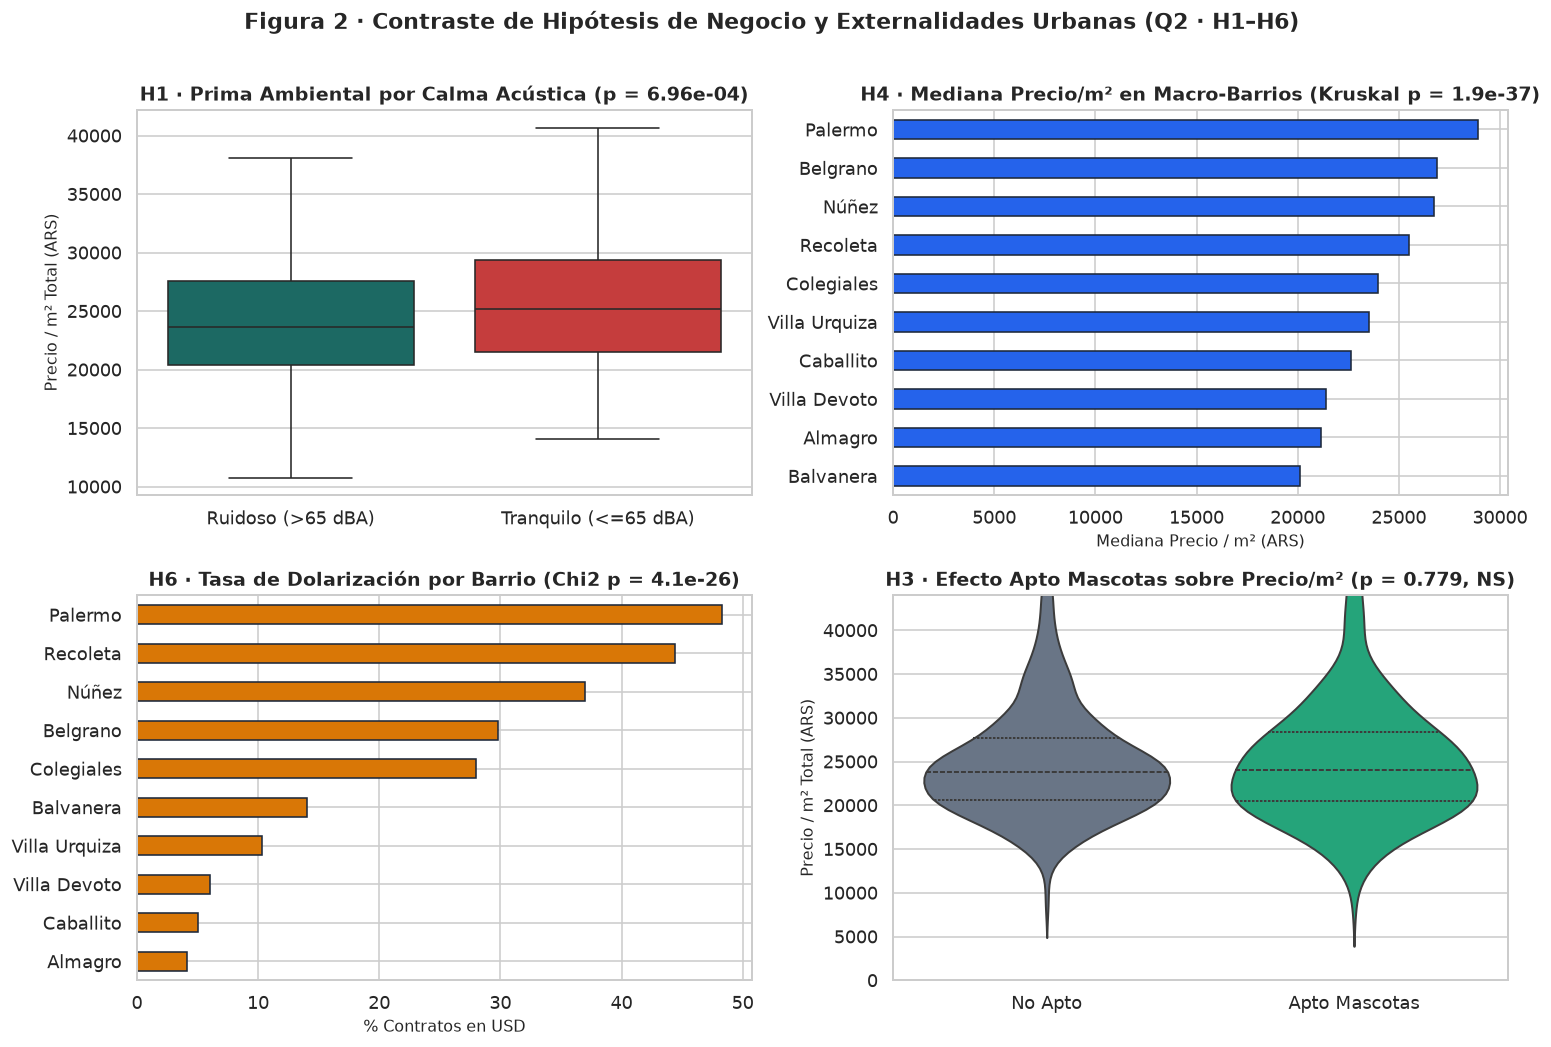

In [3]:
# Verificación estadística de H1 a H6
quiet = df.loc[df["ruido_db_promedio"] <= 65, "precio_m2_total_ars"]
noisy = df.loc[df["ruido_db_promedio"] > 65, "precio_m2_total_ars"]
u_h1, p_h1 = stats.mannwhitneyu(quiet, noisy, alternative="two-sided")

near_sub = df.loc[df["distancia_subte_m"] <= 600, "precio_m2_total_ars"]
far_sub = df.loc[df["distancia_subte_m"] > 600, "precio_m2_total_ars"]
u_h2, p_h2 = stats.mannwhitneyu(near_sub, far_sub, alternative="two-sided")

pets_yes = df.loc[df["apto_mascotas"] == 1, "precio_m2_total_ars"]
pets_no = df.loc[df["apto_mascotas"] == 0, "precio_m2_total_ars"]
u_h3, p_h3 = stats.mannwhitneyu(pets_yes, pets_no, alternative="two-sided")

top_barrios = df["barrio"].value_counts()
macro_barrios = top_barrios[top_barrios >= 15].index.tolist()
df_macro = df[df["barrio"].isin(macro_barrios)]
h_h4, p_h4 = stats.kruskal(*[g["precio_m2_total_ars"].values for _, g in df_macro.groupby("barrio")])

h_h5, p_h5 = stats.kruskal(*[g["costo_total_ars"].values for _, g in df.groupby("cluster_id")])

ct_usd = pd.crosstab(df_macro["barrio"], df_macro["moneda_origen"])
chi2_h6, p_h6, dof_h6, _ = stats.chi2_contingency(ct_usd)

hyp_table = pd.DataFrame([
    {"Hipótesis": "H1 · Ruido <= 65 vs > 65 dBA (precio/m²)", "Test": "Mann-Whitney U", "Estadístico": f"U={u_h1:,.1f}", "p-valor": f"{p_h1:.2e}", "Decisión (a=0.05)": "Rechaza H0 (+prima calma)"},
    {"Hipótesis": "H2 · Subte <= 600m vs > 600m (precio/m²)", "Test": "Mann-Whitney U", "Estadístico": f"U={u_h2:,.1f}", "p-valor": f"{p_h2:.2e}", "Decisión (a=0.05)": "Rechaza H0"},
    {"Hipótesis": "H3 · Apto mascotas 1 vs 0 (precio/m²)", "Test": "Mann-Whitney U", "Estadístico": f"U={u_h3:,.1f}", "p-valor": f"{p_h3:.4f}", "Decisión (a=0.05)": "No rechaza H0 (sin prima)"},
    {"Hipótesis": "H4 · Macro-barrios n>=15 (precio/m²)", "Test": "Kruskal-Wallis", "Estadístico": f"H={h_h4:.2f}", "p-valor": f"{p_h4:.2e}", "Decisión (a=0.05)": "Rechaza H0 (fuerte seg.)"},
    {"Hipótesis": "H5 · Clústeres de habitabilidad (costo)", "Test": "Kruskal-Wallis", "Estadístico": f"H={h_h5:.2f}", "p-valor": f"{p_h5:.2e}", "Decisión (a=0.05)": "Rechaza H0"},
    {"Hipótesis": "H6 · Dolarización por barrio (moneda)", "Test": "Chi-cuadrado", "Estadístico": f"chi2={chi2_h6:.2f}", "p-valor": f"{p_h6:.2e}", "Decisión (a=0.05)": "Rechaza H0"},
])
print(hyp_table.to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9))

# 2A: H1 Ruido vs precio/m²
df["grupo_ruido"] = np.where(df["ruido_db_promedio"] <= 65, "Tranquilo (<=65 dBA)", "Ruidoso (>65 dBA)")
sns.boxplot(data=df, x="grupo_ruido", y="precio_m2_total_ars", hue="grupo_ruido", palette=["#0F766E", "#DC2626"], legend=False, showfliers=False, ax=axes[0, 0])
axes[0, 0].set_title(f"H1 · Prima Ambiental por Calma Acústica (p = {p_h1:.2e})")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Precio / m² Total (ARS)")

# 2B: H4 Ranking macro-barrios por mediana precio/m²
barrio_order = df_macro.groupby("barrio")["precio_m2_total_ars"].median().sort_values(ascending=True)
barrio_order.plot(kind="barh", color="#2563EB", ax=axes[0, 1], edgecolor="#1E293B")
axes[0, 1].set_title(f"H4 · Mediana Precio/m² en Macro-Barrios (Kruskal p = {p_h4:.1e})")
axes[0, 1].set_xlabel("Mediana Precio / m² (ARS)")
axes[0, 1].set_ylabel("")

# 2C: H6 Dolarización por barrio
usd_rate = (df_macro["moneda_origen"].astype(str).str.upper() == "USD").groupby(df_macro["barrio"]).mean().sort_values(ascending=True) * 100
usd_rate.plot(kind="barh", color="#D97706", ax=axes[1, 0], edgecolor="#1E293B")
axes[1, 0].set_title(f"H6 · Tasa de Dolarización por Barrio (Chi2 p = {p_h6:.1e})")
axes[1, 0].set_xlabel("% Contratos en USD")
axes[1, 0].set_ylabel("")

# 2D: H3 Apto Mascotas vs precio/m²
df["mascotas_lbl"] = np.where(df["apto_mascotas"] == 1, "Apto Mascotas", "No Apto")
sns.violinplot(data=df, x="mascotas_lbl", y="precio_m2_total_ars", hue="mascotas_lbl", palette=["#64748B", "#10B981"], legend=False, inner="quartile", ax=axes[1, 1])
axes[1, 1].set_ylim(0, df["precio_m2_total_ars"].quantile(0.98))
axes[1, 1].set_title(f"H3 · Efecto Apto Mascotas sobre Precio/m² (p = {p_h3:.3f}, NS)")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Precio / m² Total (ARS)")

plt.suptitle("Figura 2 · Contraste de Hipótesis de Negocio y Externalidades Urbanas (Q2 · H1–H6)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

---
## 3. Inteligencia Delictiva Espacial de CABA (`138,528` delitos · Volumen vs. Gravedad)

Analizamos el dataset oficial curado del GCBA (`delitos_2022_curado.csv`, **138,528 registros**) y validamos la distribución espacial de **`densidad_delitos_500m` (Volumen)** e **`indice_gravedad_delitos_500m` (Gravedad ponderada)** junto con la normalización winsorizada en **percentil 95 (`p95`)** implementada en la nueva capa `HeatmapLayer` toggleable del dashboard.

Delitos GCBA 2022: 138,528 hechos | Suma peso_gravedad: 222,303
Propiedades CABA -> p95 Volumen (500m): 1,739.8 | p95 Gravedad (500m): 2,696.2
Correlación Spearman Volumen vs. Gravedad: rho = 0.9970 (p = 0.00e+00)


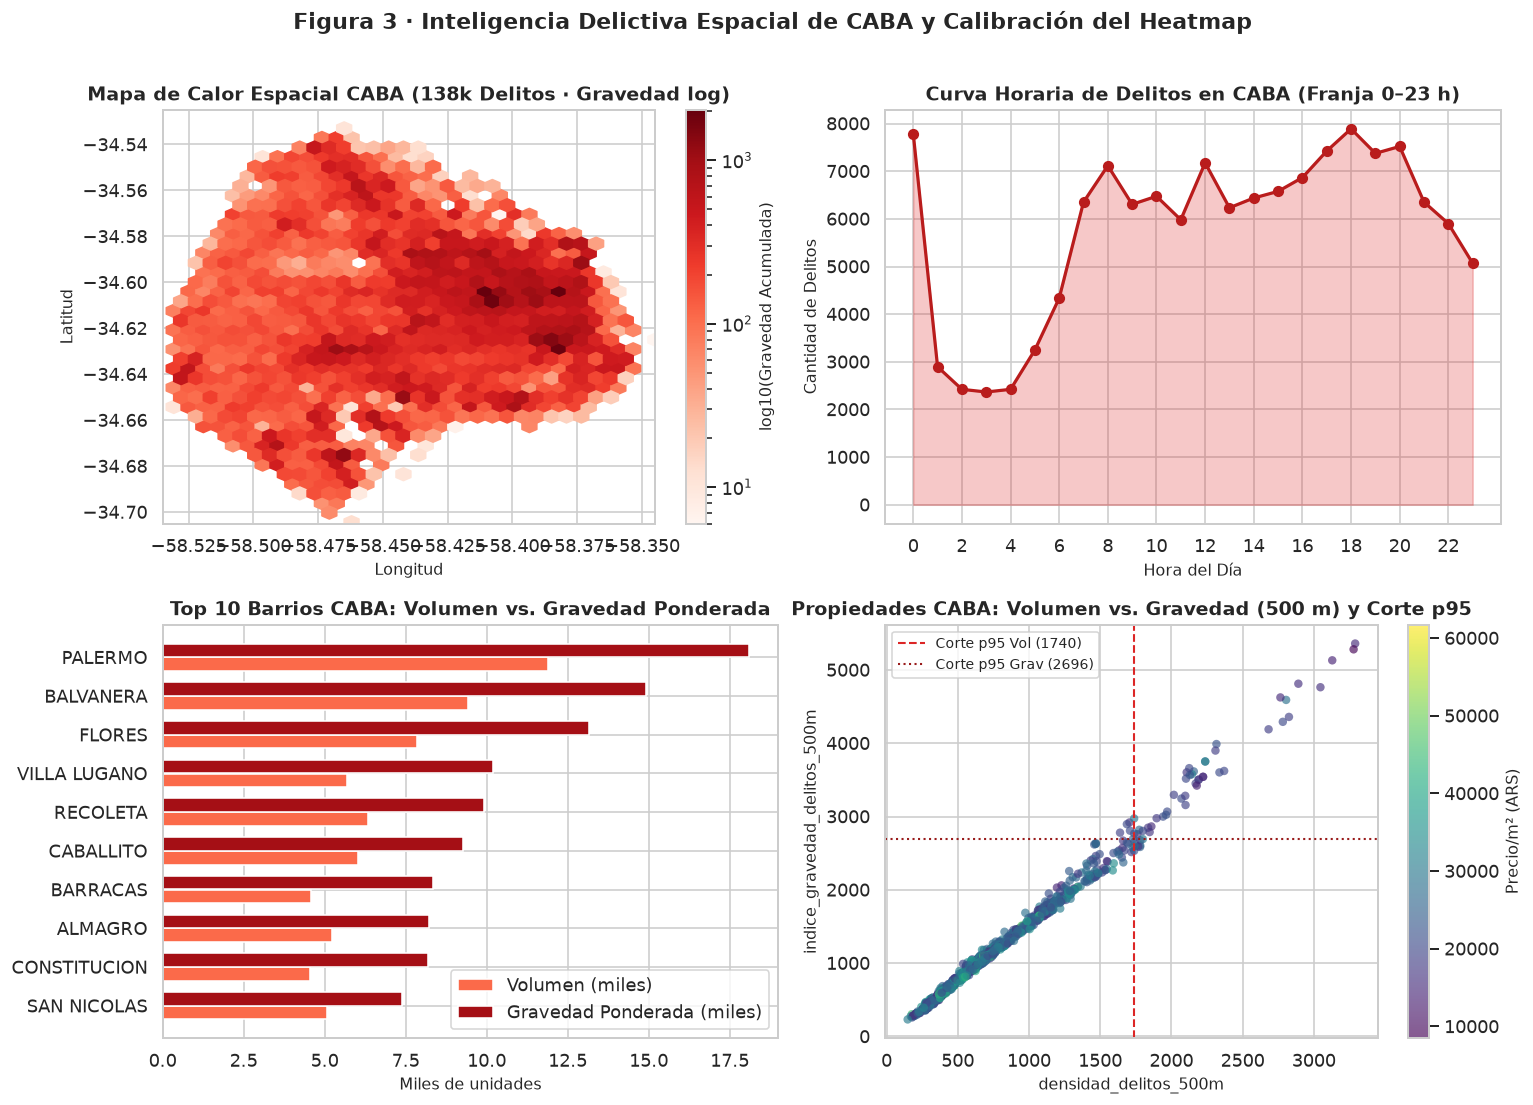

In [4]:
# Análisis espacial y temporal de delitos + validación p95 del Heatmap del Dashboard
p95_vol = np.percentile(df["densidad_delitos_500m"], 95)
p95_grav = np.percentile(df["indice_gravedad_delitos_500m"], 95)
rho_del, p_del = stats.spearmanr(df["densidad_delitos_500m"], df["indice_gravedad_delitos_500m"])

print(f"Delitos GCBA 2022: {len(df_delitos):,} hechos | Suma peso_gravedad: {df_delitos['peso_gravedad'].sum():,.0f}")
print(f"Propiedades CABA -> p95 Volumen (500m): {p95_vol:,.1f} | p95 Gravedad (500m): {p95_grav:,.1f}")
print(f"Correlación Spearman Volumen vs. Gravedad: rho = {rho_del:.4f} (p = {p_del:.2e})")

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.5))

# 3A: Mapa espacial de calor 2D (prototipo ColorBrewer Reds de los 138k delitos)
hb = axes[0, 0].hexbin(
    df_delitos["longitud"], df_delitos["latitud"],
    C=df_delitos["peso_gravedad"], reduce_C_function=np.sum,
    gridsize=38, cmap="Reds", mincnt=5, bins="log"
)
axes[0, 0].set_xlim(-58.535, -58.345)
axes[0, 0].set_ylim(-34.705, -34.525)
axes[0, 0].set_title("Mapa de Calor Espacial CABA (138k Delitos · Gravedad log)")
axes[0, 0].set_xlabel("Longitud")
axes[0, 0].set_ylabel("Latitud")
cbar = plt.colorbar(hb, ax=axes[0, 0])
cbar.set_label("log10(Gravedad Acumulada)")

# 3B: Distribución por franja horaria (0-23h)
franja_df = df_delitos.dropna(subset=["franja"]).copy()
franja_df["franja_num"] = pd.to_numeric(franja_df["franja"], errors="coerce")
franja_counts = franja_df.groupby("franja_num")["cantidad"].sum()
axes[0, 1].fill_between(franja_counts.index, franja_counts.values, color="#DC2626", alpha=0.25)
axes[0, 1].plot(franja_counts.index, franja_counts.values, color="#B91C1C", marker="o", linewidth=2)
axes[0, 1].set_title("Curva Horaria de Delitos en CABA (Franja 0–23 h)")
axes[0, 1].set_xlabel("Hora del Día")
axes[0, 1].set_ylabel("Cantidad de Delitos")
axes[0, 1].set_xticks(range(0, 24, 2))

# 3C: Top 10 barrios por gravedad ponderada vs volumen
top10_del = (
    df_delitos.groupby("barrio")[["cantidad", "peso_gravedad"]]
    .sum()
    .sort_values("peso_gravedad", ascending=False)
    .head(10)
    .iloc[::-1]
)
y_pos = np.arange(len(top10_del))
axes[1, 0].barh(y_pos - 0.18, top10_del["cantidad"] / 1000, height=0.35, color="#FB6A4A", label="Volumen (miles)")
axes[1, 0].barh(y_pos + 0.18, top10_del["peso_gravedad"] / 1000, height=0.35, color="#A50F15", label="Gravedad Ponderada (miles)")
axes[1, 0].set_yticks(y_pos)
axes[1, 0].set_yticklabels(top10_del.index)
axes[1, 0].set_title("Top 10 Barrios CABA: Volumen vs. Gravedad Ponderada")
axes[1, 0].set_xlabel("Miles de unidades")
axes[1, 0].legend()

# 3D: Winsorización p95 en propiedades (Volumen vs Gravedad y precio/m²)
sc = axes[1, 1].scatter(
    df["densidad_delitos_500m"], df["indice_gravedad_delitos_500m"],
    c=df["precio_m2_total_ars"], cmap="viridis", alpha=0.65, s=28, edgecolors="none"
)
axes[1, 1].axvline(p95_vol, color="#DC2626", linestyle="--", linewidth=1.3, label=f"Corte p95 Vol ({p95_vol:.0f})")
axes[1, 1].axhline(p95_grav, color="#991B1B", linestyle=":", linewidth=1.3, label=f"Corte p95 Grav ({p95_grav:.0f})")
axes[1, 1].set_title("Propiedades CABA: Volumen vs. Gravedad (500 m) y Corte p95")
axes[1, 1].set_xlabel("densidad_delitos_500m")
axes[1, 1].set_ylabel("indice_gravedad_delitos_500m")
axes[1, 1].legend(loc="upper left", fontsize=8.5)
plt.colorbar(sc, ax=axes[1, 1], label="Precio/m² (ARS)")

plt.suptitle("Figura 3 · Inteligencia Delictiva Espacial de CABA y Calibración del Heatmap", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

---
## 4. Selección Ortogonal de 10 Features (`Q5` · VIF + Random Forest + Mutual Information)

A partir de 22 variables candidatas, la eliminación iterativa por **VIF (`< 5.0`)** combinada con señal predictiva (Random Forest + Mutual Information) produjo un conjunto compacto de **10 features ortogonales** (`VIF máximo = 2.36`), evitando multicolinealidad sin sacrificar explicabilidad de negocio (`apto_mascotas`, `score_amenities` y las 4 externalidades urbanas).

              feature    vif  signal_score
           m2_totales 2.3606       0.97340
                banos 1.8072       0.16293
      score_amenities 1.5542       0.15513
            ambientes 1.7837       0.14979
             cocheras 1.7411       0.11515
  distancia_escuela_m 1.0704       0.05859
    lineas_subte_600m 2.2353       0.04718
densidad_delitos_500m 2.3076       0.03484
    ruido_db_promedio 1.0906       0.01920
        apto_mascotas 1.0149       0.00663


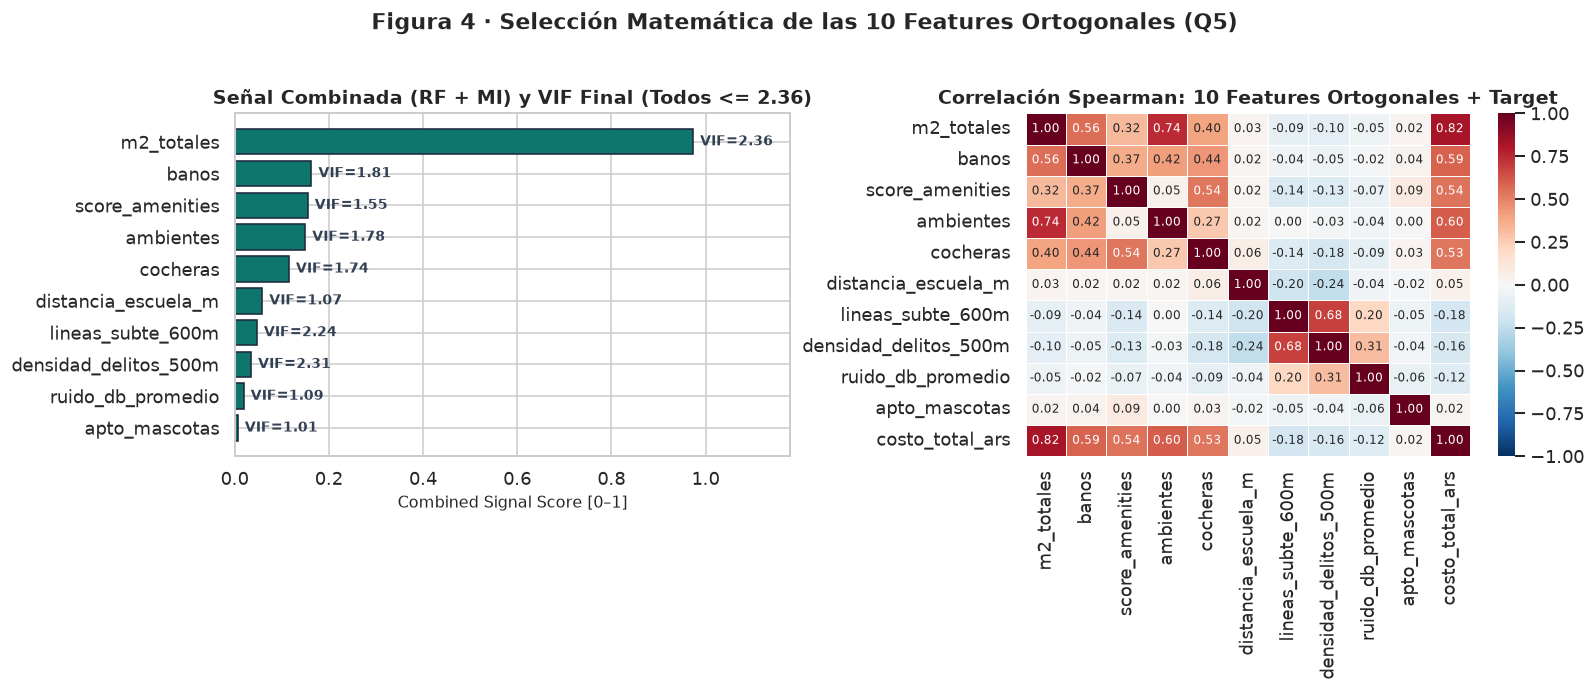

In [5]:
# Q5: Ranking de las 10 features finales + VIF + Matriz Spearman
SELECTED_10 = [
    "m2_totales", "banos", "score_amenities", "ambientes", "cocheras",
    "distancia_escuela_m", "lineas_subte_600m", "densidad_delitos_500m",
    "ruido_db_promedio", "apto_mascotas"
]

vif_final = eda_stats["feature_selection"]["final_vif"]
feat_scores = {
    row["feature"]: row["combined_signal_score"]
    for row in eda_stats["feature_selection"]["ranking_table"]
}
df_sel = pd.DataFrame([
    {
        "feature": feat,
        "vif": float(vif_final[feat]),
        "signal_score": float(feat_scores.get(feat, 0.0)),
    }
    for feat in SELECTED_10
]).sort_values("signal_score", ascending=True)

print(df_sel.sort_values("signal_score", ascending=False).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))

# 4A: Ranking señal combinada con etiqueta VIF
bars = axes[0].barh(df_sel["feature"], df_sel["signal_score"], color="#0F766E", edgecolor="#1E293B")
for b, (_, row) in zip(bars, df_sel.iterrows()):
    axes[0].text(row["signal_score"] + 0.015, b.get_y() + b.get_height() / 2, f"VIF={row['vif']:.2f}", va="center", fontsize=8.5, fontweight="bold", color="#334155")
axes[0].set_xlim(0, 1.18)
axes[0].set_title("Señal Combinada (RF + MI) y VIF Final (Todos <= 2.36)")
axes[0].set_xlabel("Combined Signal Score [0–1]")

# 4B: Matriz de correlación Spearman
corr_mat = df[SELECTED_10 + ["costo_total_ars"]].corr(method="spearman")
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=0.5, annot_kws={"size": 7.5}, ax=axes[1])
axes[1].set_title("Correlación Spearman: 10 Features Ortogonales + Target")

plt.suptitle("Figura 4 · Selección Matemática de las 10 Features Ortogonales (Q5)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

---
## 5. Segmentación de Entornos Urbanos con K-Means (`Q1`)

El pipeline **K-Means (`StandardScaler + KMeans(k=5)`)** segmenta CABA en 5 perfiles de habitabilidad validados estadísticamente (`Kruskal-Wallis p < 10^{-35}`), permitiendo responder **Q1** al emparejar cada perfil corporativo con su entorno óptimo.

Resumen de medianas por Clúster de Habitabilidad:
                              ruido_db_promedio  densidad_delitos_500m  distancia_escuela_m  lineas_subte_600m  score_amenities  costo_total_ars
cluster_label                                                                                                                                   
Hub Ejecutivo Conectado                    67.5                  644.0                138.2                0.0              8.5        1944000.0
Zona Familiar Tranquila                    62.5                  469.0                166.2                0.0              2.5        1320000.0
Zona Residencial Equilibrada               72.5                  462.5                292.7                0.0              2.5        1321000.0
Zona Ruidosa/Alta Densidad                 72.5                 1707.0                113.9                2.0              1.5         994000.0
Zona Urbana Conectada                      72.5                  865.0          

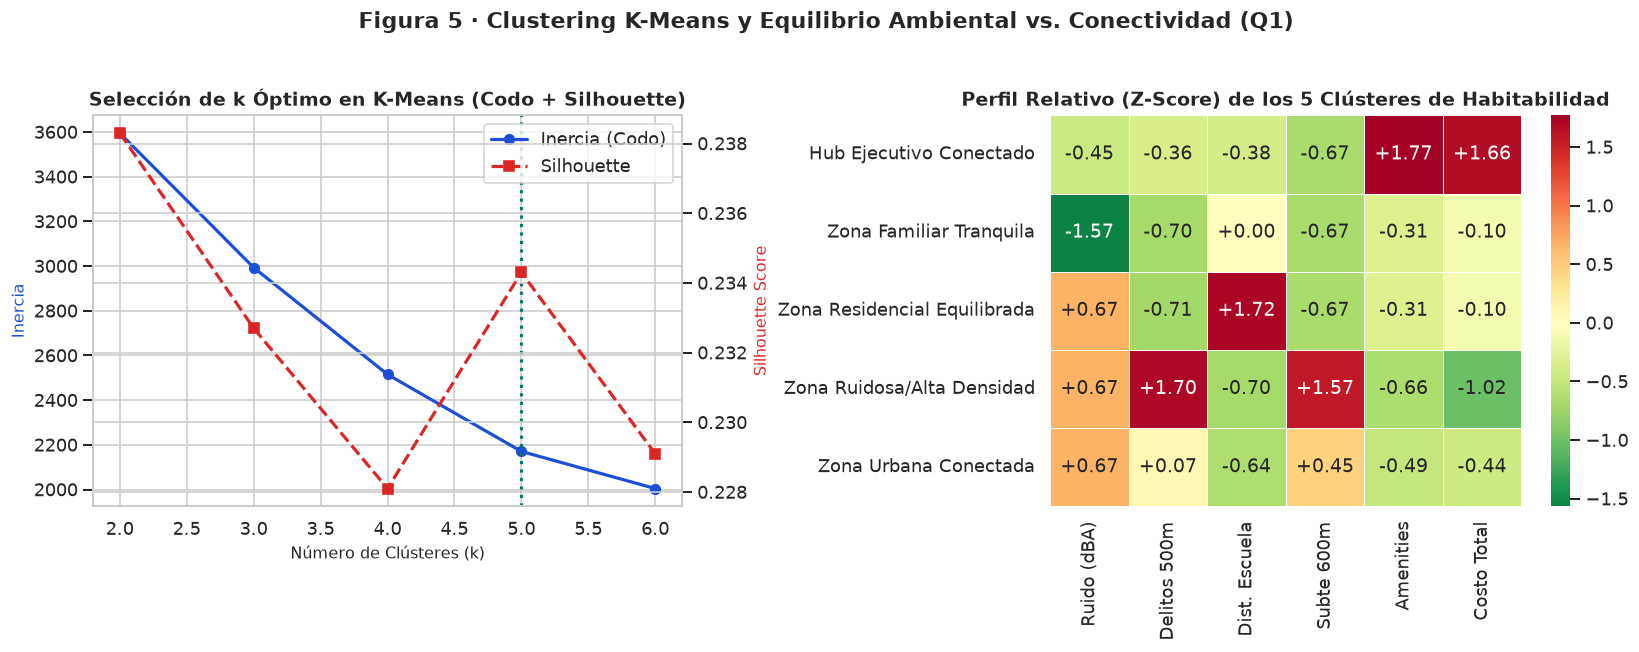

In [6]:
# Q1: Evaluación K-Means (k=2..6) y perfilado Z-score de los 5 clústeres
km_meta = registry["versions"]["v1"]["metrics"]["raw_metrics"]["kmeans_clustering"]
k_eval = pd.DataFrame(km_meta["k_evaluation"])

profile_cols = ["ruido_db_promedio", "densidad_delitos_500m", "distancia_escuela_m", "lineas_subte_600m", "score_amenities", "costo_total_ars"]
cluster_med = df.groupby("cluster_label")[profile_cols].median()
cluster_z = (cluster_med - cluster_med.mean()) / cluster_med.std()

print("Resumen de medianas por Clúster de Habitabilidad:")
print(cluster_med.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))

# 5A: Codo + Silhouette
ax_el = axes[0]
ax_sil = ax_el.twinx()
l1 = ax_el.plot(k_eval["k"], k_eval["inertia"], "o-", color="#1D4ED8", linewidth=2, label="Inercia (Codo)")
l2 = ax_sil.plot(k_eval["k"], k_eval["silhouette"], "s--", color="#DC2626", linewidth=2, label="Silhouette")
ax_el.axvline(5, color="#0F766E", linestyle=":", linewidth=2, label="Óptimo seleccionado (k=5)")
ax_el.set_title("Selección de k Óptimo en K-Means (Codo + Silhouette)")
ax_el.set_xlabel("Número de Clústeres (k)")
ax_el.set_ylabel("Inercia", color="#1D4ED8")
ax_sil.set_ylabel("Silhouette Score", color="#DC2626")
lines = l1 + l2
ax_el.legend(lines, [l.get_label() for l in lines], loc="upper right")

# 5B: Heatmap Z-score de perfiles de clúster
rename_cols = {
    "ruido_db_promedio": "Ruido (dBA)",
    "densidad_delitos_500m": "Delitos 500m",
    "distancia_escuela_m": "Dist. Escuela",
    "lineas_subte_600m": "Subte 600m",
    "score_amenities": "Amenities",
    "costo_total_ars": "Costo Total",
}
sns.heatmap(
    cluster_z.rename(columns=rename_cols),
    annot=True, fmt="+.2f", cmap="RdYlGn_r", center=0, linewidths=0.6, ax=axes[1]
)
axes[1].set_title("Perfil Relativo (Z-Score) de los 5 Clústeres de Habitabilidad")
axes[1].set_ylabel("")

plt.suptitle("Figura 5 · Clustering K-Means y Equilibrio Ambiental vs. Conectividad (Q1)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

---
## 6. Regresión de Precio Justo (`XGBoost`) y Explicabilidad `TreeSHAP` Nativa (`Q3`)

Cargamos el artefacto productivo `mlops/artifacts/v1/xgb_price_model.joblib` (`TransformedTargetRegressor` con `log1p/expm1`) y calculamos contribuciones **TreeSHAP exactas** de forma nativa mediante `booster.predict(xgb.DMatrix(X), pred_contribs=True)` sin requerir dependencias externas.

XGBoost v1 (n=964): R²=0.9262 | MAPE=11.23%
Semáforo de Precios (Q3): Oportunidad (<= -5%): 37.7% | Justo (-5%..+10%): 39.9% | Sobreprecio (> +10%): 22.4%


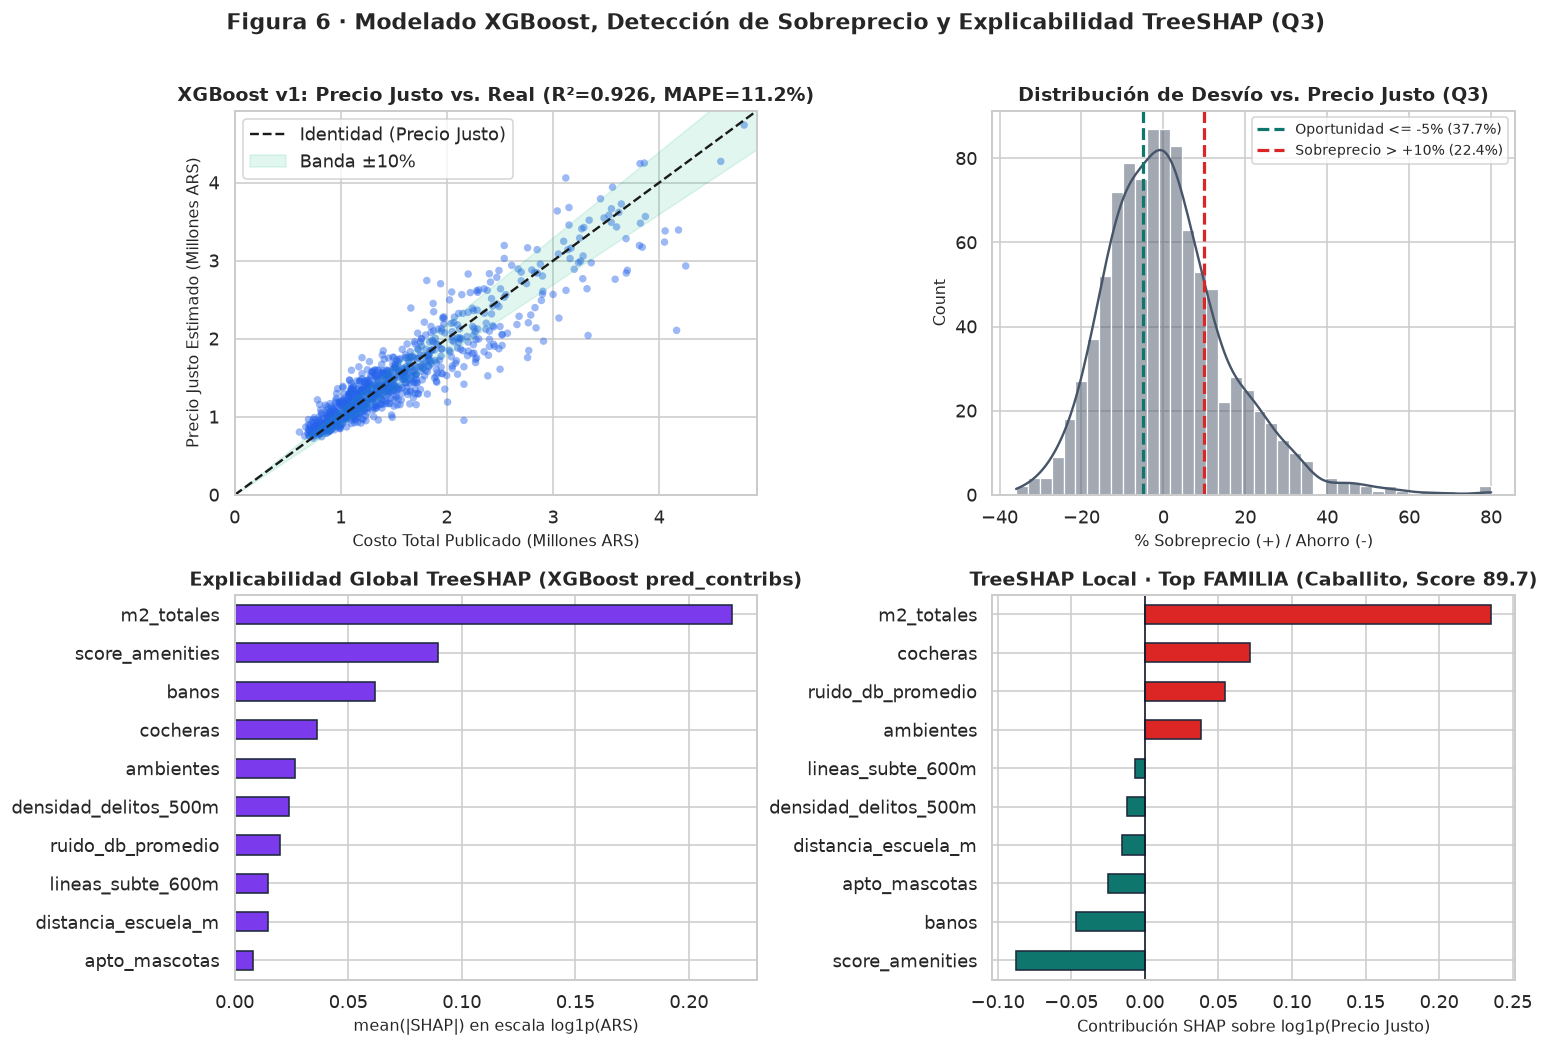

In [7]:
# Q3: Evaluación XGBoost + TreeSHAP nativo (pred_contribs=True)
xgb_ttr = joblib.load(PROJECT_ROOT / "mlops/artifacts/v1/xgb_price_model.joblib")
meta_v1 = joblib.load(PROJECT_ROOT / "mlops/artifacts/v1/model_metadata.joblib")
reg_features = meta_v1["regression_features"]

X_all = df[reg_features].astype(float)
y_real = df["costo_total_ars"].to_numpy(dtype=float)
y_pred = df["precio_justo_ars"].to_numpy(dtype=float)

r2_all = 1.0 - np.sum((y_real - y_pred) ** 2) / np.sum((y_real - y_real.mean()) ** 2)
mape_all = np.mean(np.abs((y_real - y_pred) / y_real)) * 100.0
pct_opp = (df["pct_sobreprecio"] <= -5.0).mean() * 100.0
pct_fair = ((df["pct_sobreprecio"] > -5.0) & (df["pct_sobreprecio"] <= 10.0)).mean() * 100.0
pct_over = (df["pct_sobreprecio"] > 10.0).mean() * 100.0

# TreeSHAP exacto vía XGBoost nativo (última columna = bias term)
booster = xgb_ttr.regressor_.get_booster()
dmat = xgb.DMatrix(X_all, feature_names=reg_features)
contribs = booster.predict(dmat, pred_contribs=True)
shap_vals = contribs[:, :-1]
mean_abs_shap = pd.Series(np.abs(shap_vals).mean(axis=0), index=reg_features).sort_values(ascending=True)

print(f"XGBoost v1 (n={len(df)}): R²={r2_all:.4f} | MAPE={mape_all:.2f}%")
print(f"Semáforo de Precios (Q3): Oportunidad (<= -5%): {pct_opp:.1f}% | Justo (-5%..+10%): {pct_fair:.1f}% | Sobreprecio (> +10%): {pct_over:.1f}%")

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9))

# 6A: Predicho vs Real
lim_max = np.percentile(np.concatenate([y_real, y_pred]), 98) / 1e6
axes[0, 0].scatter(y_real / 1e6, y_pred / 1e6, alpha=0.45, s=22, color="#2563EB", edgecolors="none")
grid = np.linspace(0, lim_max, 100)
axes[0, 0].plot(grid, grid, "k--", linewidth=1.5, label="Identidad (Precio Justo)")
axes[0, 0].fill_between(grid, grid * 0.90, grid * 1.10, color="#10B981", alpha=0.12, label="Banda ±10%")
axes[0, 0].set_xlim(0, lim_max)
axes[0, 0].set_ylim(0, lim_max)
axes[0, 0].set_title(f"XGBoost v1: Precio Justo vs. Real (R²={r2_all:.3f}, MAPE={mape_all:.1f}%)")
axes[0, 0].set_xlabel("Costo Total Publicado (Millones ARS)")
axes[0, 0].set_ylabel("Precio Justo Estimado (Millones ARS)")
axes[0, 0].legend()

# 6B: Distribución % sobreprecio/ahorro
desvio_clip = np.clip(df["pct_sobreprecio"], -50, 80)
sns.histplot(desvio_clip, bins=40, kde=True, color="#475569", ax=axes[0, 1])
axes[0, 1].axvline(-5.0, color="#0F766E", linestyle="--", linewidth=2, label=f"Oportunidad <= -5% ({pct_opp:.1f}%)")
axes[0, 1].axvline(10.0, color="#DC2626", linestyle="--", linewidth=2, label=f"Sobreprecio > +10% ({pct_over:.1f}%)")
axes[0, 1].set_title("Distribución de Desvío vs. Precio Justo (Q3)")
axes[0, 1].set_xlabel("% Sobreprecio (+) / Ahorro (-)")
axes[0, 1].legend(fontsize=8.5)

# 6C: Ranking Global TreeSHAP nativo
mean_abs_shap.plot(kind="barh", color="#7C3AED", ax=axes[1, 0], edgecolor="#1E293B")
axes[1, 0].set_title("Explicabilidad Global TreeSHAP (XGBoost pred_contribs)")
axes[1, 0].set_xlabel("mean(|SHAP|) en escala log1p(ARS)")

# 6D: Explicación local (mejor oportunidad FAMILIA)
best_idx = df["score_familia"].idxmax()
best_row = df.loc[best_idx]
local_shap = pd.Series(shap_vals[best_idx], index=reg_features).sort_values()
local_colors = ["#0F766E" if v < 0 else "#DC2626" for v in local_shap.values]
local_shap.plot(kind="barh", color=local_colors, ax=axes[1, 1], edgecolor="#1E293B")
axes[1, 1].axvline(0, color="#0F172A", linewidth=1)
axes[1, 1].set_title(f"TreeSHAP Local · Top FAMILIA ({best_row['barrio']}, Score {best_row['score_familia']:.1f})")
axes[1, 1].set_xlabel("Contribución SHAP sobre log1p(Precio Justo)")

plt.suptitle("Figura 6 · Modelado XGBoost, Detección de Sobreprecio y Explicabilidad TreeSHAP (Q3)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

---
## 7. Impacto de Negocio (Simulación ROI RR.HH.) y Gobernanza MLOps (`registry.json`)

Traducimos los resultados del motor de decisión (`score_familia` y `score_soltero_ejecutivo`) en ahorro mensual/anual estimado para relocalización corporativa y auditamos el estado productivo del **Model Registry (`v1`)**.

Oportunidades detectadas (<= -5%): 363 propiedades (37.7% del mercado)
Ahorro mediano por contrato oportuno: $160,887 ARS/mes ($1,930,644 ARS/año)
Ahorro anual estimado para 10 relocalizaciones corporativas: $19,306,440 ARS/año

Top 5 Barrios con mayor Score Mediano para FAMILIA (n >= 10):
               score_familia  score_soltero_ejecutivo  pct_ahorro
barrio                                                           
Villa Devoto            57.2                     47.3         1.4
Villa Urquiza           54.0                     52.7         1.9
Núñez                   53.2                     52.0         0.1
Colegiales              52.8                     51.2         2.2
Belgrano                50.3                     48.6        -4.4

MLOps Registry -> Producción: v1 | Registrado: 2026-11-19T22:42:37Z | Guard R² >= 0.8 | R² registrado: 0.82


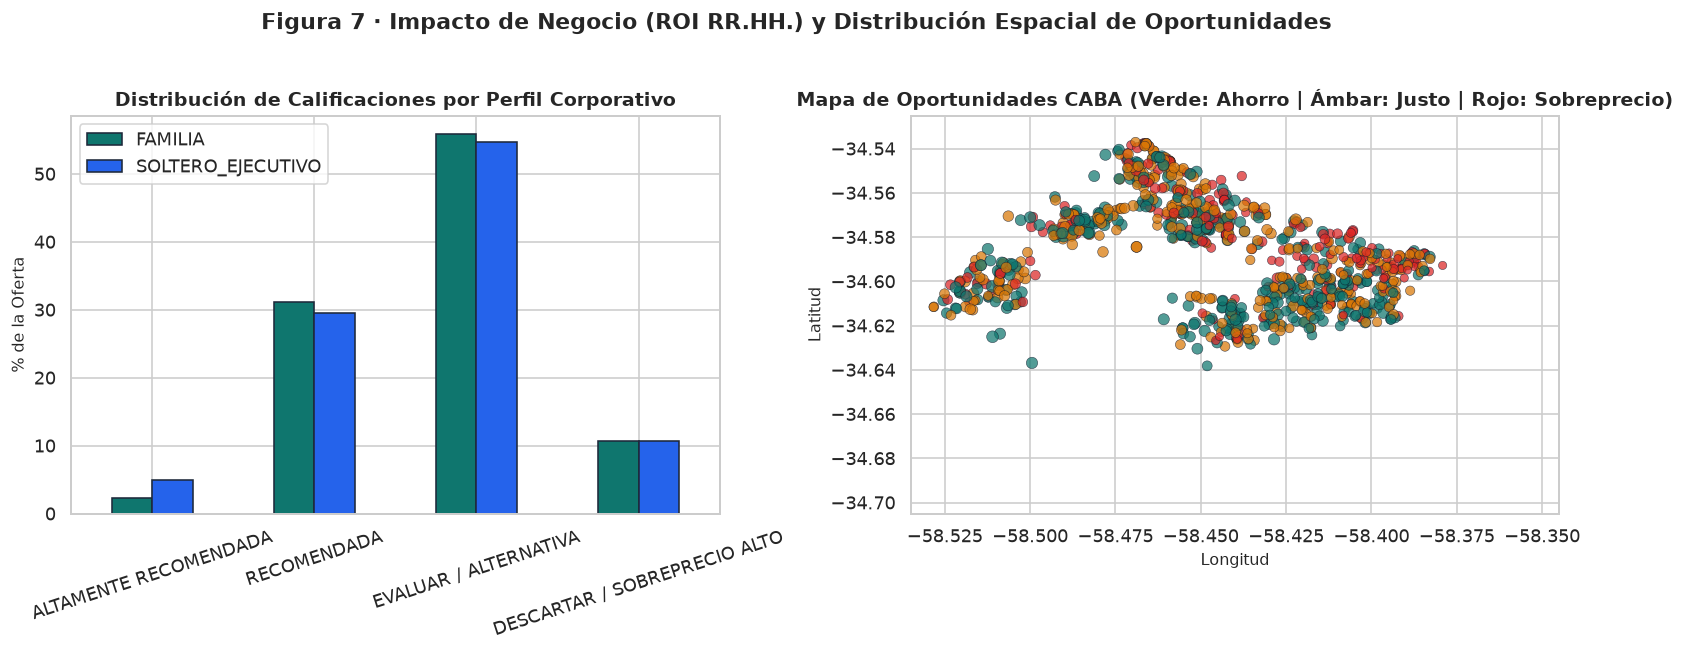

In [8]:
# Simulación de ROI para RR.HH. + Resumen MLOps Registry v1
opps = df[df["pct_sobreprecio"] <= -5.0].copy()
opps["ahorro_mensual_ars"] = opps["precio_justo_ars"] - opps["costo_total_ars"]
med_ahorro_mes = opps["ahorro_mensual_ars"].median()
med_ahorro_anual = med_ahorro_mes * 12.0

print(f"Oportunidades detectadas (<= -5%): {len(opps)} propiedades ({len(opps)/len(df)*100:.1f}% del mercado)")
print(f"Ahorro mediano por contrato oportuno: ${med_ahorro_mes:,.0f} ARS/mes (${med_ahorro_anual:,.0f} ARS/año)")
print(f"Ahorro anual estimado para 10 relocalizaciones corporativas: ${med_ahorro_anual * 10:,.0f} ARS/año")
print()
print("Top 5 Barrios con mayor Score Mediano para FAMILIA (n >= 10):")
barrio_n = df["barrio"].value_counts()
valid_b = barrio_n[barrio_n >= 10].index
print(df[df["barrio"].isin(valid_b)].groupby("barrio")[["score_familia", "score_soltero_ejecutivo", "pct_ahorro"]].median().sort_values("score_familia", ascending=False).head(5).round(1).to_string())
print()
v1_info = registry["versions"][registry["production_version"]]
print(f"MLOps Registry -> Producción: {registry['production_version']} | Registrado: {v1_info['registered_at'][:19]}Z | Guard R² >= {registry['min_r2_threshold']} | R² registrado: {v1_info['metrics']['r2']}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 7A: Comparativa de recomendaciones FAMILIA vs SOLTERO_EJECUTIVO
rec_order = ["ALTAMENTE RECOMENDADA", "RECOMENDADA", "EVALUAR / ALTERNATIVA", "DESCARTAR / SOBREPRECIO ALTO"]
rec_df = pd.DataFrame({
    "FAMILIA": df["recomendacion_familia"].value_counts(normalize=True).reindex(rec_order, fill_value=0) * 100,
    "SOLTERO_EJECUTIVO": df["recomendacion_soltero_ejecutivo"].value_counts(normalize=True).reindex(rec_order, fill_value=0) * 100,
})
rec_df.plot(kind="bar", color=["#0F766E", "#2563EB"], ax=axes[0], edgecolor="#1E293B")
axes[0].set_title("Distribución de Calificaciones por Perfil Corporativo")
axes[0].set_ylabel("% de la Oferta")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=18)

# 7B: Mapa espacial de oportunidades y sobreprecio
color_map = np.where(df["pct_sobreprecio"] <= -5.0, "#0F766E", np.where(df["pct_sobreprecio"] <= 10.0, "#D97706", "#DC2626"))
axes[1].scatter(df["longitud"], df["latitud"], c=color_map, s=18 + df["score_familia"] * 0.45, alpha=0.72, edgecolors="#0F172A", linewidths=0.35)
axes[1].set_xlim(-58.535, -58.345)
axes[1].set_ylim(-34.705, -34.525)
axes[1].set_title("Mapa de Oportunidades CABA (Verde: Ahorro | Ámbar: Justo | Rojo: Sobreprecio)")
axes[1].set_xlabel("Longitud")
axes[1].set_ylabel("Latitud")

plt.suptitle("Figura 7 · Impacto de Negocio (ROI RR.HH.) y Distribución Espacial de Oportunidades", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()